# 漢字姓名とカタカナ姓名の２値分類
`dataset_j.ipynb`で作成したデータを使い、漢字姓名とカタカナ姓名の組を「正しい組み合わせ／誤った組み合わせ」に分類するTransformerモデルを学習・評価します。最後に、学習済みモデルをTorchScript形式で書き出します。

## 対象
- 日本人と別名付きの外国人など、
- 空白区切りを作らない
漢字姓名とカタカナ姓名を `漢字_カタカナ` の形式で扱い、間に空白を入れずに分類します。日本人名や別名を持つ外国人名などを対象とする想定です。

## load data
バージョンや学習条件、データ・モデルの保存先を設定し、乱数シードを固定します。続けて学習データから文字語彙を作り、圧縮CSV形式の学習・検証・テストデータを読み込みます。

In [1]:
ver="2.0o"

branch_suffix="_j" # training branch suffix
import os


In [2]:
d_model=256 # emb_size
nhead=4
num_layer=4
dropout=0.1
batch_size=64
max_len=100
hardK=4
epochs=100
patience=5

lr=3e-4
warmup_epochs=10
use_cosine=True
grad_clip=0.5
min_delta=1e-4

# 敵対的なhard negativeを学習時に生成するか
use_hard_negative=True

# 空白抜く率
noblank_ratio=0.2

train_file='train_j.csv.gz'
valid_file='valid_j.csv.gz'
test_file='test_j.csv.gz'

debug=False
if debug:
    epochs=2

In [ ]:
MODEL_DIR=f'model/model{branch_suffix}.{ver}'
LOG_DIR=f'logs/logs{branch_suffix}.{ver}'
DATA_DIR=f'dataset/dataset{branch_suffix}.{ver}'

ANALYSIS_DIR='/mnt/data'

In [4]:

!mkdir -p {MODEL_DIR}

In [5]:
import json

import torch
import json
import random
import numpy as np
import torch

def set_seed(seed=42):
    # Python
    random.seed(seed)

    # NumPy
    np.random.seed(seed)

    # PyTorch（CPU と GPU）
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # 再現性のために CuDNN を固定
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# 文字変換
入力文字列を大文字化して全角に統一し、濁点付きカタカナの表記揺れをまとめます。また、複数の長音記号を「ー」に置き換え、学習・推論で文字表記を揃えます。

In [6]:
import mojimoji
def normalize_moji(s: str) -> str:
    def normalize_to_fullwidth_upper(s: str) -> str:
        return mojimoji.han_to_zen(s.upper())

    REPLACE_MAP = {
        "ウ゛": "ヴ",
        "カ゛": "ガ",
        "キ゛": "ギ",
        "ク゛": "グ",
        "ケ゛": "ゲ",
        "コ゛": "ゴ",
        "サ゛": "ザ",
        "シ゛": "ジ",
        "ス゛": "ズ",
        "セ゛": "ゼ",
        "ソ゛": "ゾ",
        "タ゛": "ダ",
        "チ゛": "ヂ",
        "ツ゛": "ヅ",
        "テ゛": "デ",
        "ト゛": "ド",
        "ハ゛": "バ",
        "ヒ゛": "ビ",
        "フ゛": "ブ",
        "ヘ゛": "ベ",
        "ホ゛": "ボ",
    }

    def normalize_voiced_katakana(s: str) -> str:
        for k, v in REPLACE_MAP.items():
            s = s.replace(k, v)
        return s


    LONG_SOUND_MAP = {
        '−': 'ー',
        '-': 'ー',
        '－': 'ー',
        '—': 'ー',
        '‐': 'ー',
        '－':'ー',
    }


    return normalize_voiced_katakana(''.join(LONG_SOUND_MAP.get(c, c) for c in normalize_to_fullwidth_upper(s)))

# vocab
学習データの漢字・カタカナから1文字単位の出現頻度を集計し、文字をIDに変換する辞書を作ります。予約IDや対象外記号を除いた辞書を保存し、逆変換用の辞書も用意します。

In [7]:
import gzip
vocab={}

def set_vocab_flageddata(fname):
    with gzip.open(f'{DATA_DIR}/{fname}','rt',encoding='utf-8') as f:
        for i,l in enumerate(f):
            if i == 0:
                continue
            keys, flag= l.rstrip().split(',')
            for key in keys:
                for v in key.split('_'):
                    if v not in vocab:
                        vocab[v]=0
                    vocab[v]+=1

set_vocab_flageddata(train_file)


In [8]:
char2id={"<pad>":0,"<unk>":1, "<bos>":2, "<eos>":3,"<sep>":4,"　":5}
for k,v in vocab.items():
    if len(k)==1:

        if '●'  ==k:
           continue

        if '＿' ==k:
            continue

        if "휀" ==k:
            continue  # 外字という住基文字を削除

        char2id[k]=len(char2id)

In [9]:
id2char = {v:k for k,v in char2id.items()}

print(len(char2id))


52275


In [10]:
with open(f'{MODEL_DIR}/char2id.json','w',encoding='utf-8') as f:
    json.dump(char2id,f,ensure_ascii=False, indent=2)

In [11]:
import gzip
import csv

def load_flaged_csv(fname):
    dataset=[]
    with gzip.open(f'{DATA_DIR}/{fname}','rt',encoding='utf-8') as f:
        reader = csv.reader(f)
        for i,line in enumerate(reader):
            if i == 0:
                continue
            key,flag = line
            dataset.append([key,flag]) # flag:0 ng , flag:1 OK
    return dataset


In [12]:
train_dataset_org=load_flaged_csv(train_file)
test_dataset_org=load_flaged_csv(test_file)
valid_dataset_org=load_flaged_csv(valid_file)

In [13]:
print(len(train_dataset_org))
print(len(valid_dataset_org))
print(len(test_dataset_org))

4492858
520452
519989


## dataset  insample check
元データについて、学習データ内の重複と、検証・テストデータが学習・検証データと重複していないかを調べます。重複が見つかった場合は該当行を表示します。

In [14]:
train_dic={}
valid_dic={}
for line in train_dataset_org:
    key,flag =line
    if key in train_dic:
        print(line)
    train_dic[key]=1

In [15]:
# valid data check
for line in valid_dataset_org:
    key,flag = line
    if key in train_dic:
        print(line)
    valid_dic[key]=1

In [16]:
# valid data check
for line in test_dataset_org:
    key,flag = line
    if key in train_dic or key in valid_dic:
        print(line)

['西雲_ズクモ', '0']
['持参_ネバ', '0']


## データセットをmax_lenに合わせて長くする
2つの単語をスペース区切りで繋げる
複数サンプルの漢字・カタカナを空白で連結し、長さが `max_len` を超えない拡張データを作る関数を定義します。ラベルは `sum(flags) == len(flag)` の判定式で付与し、カタカナ側の区切りをランダムに除く処理も含みます。現在のセル実行では関数を定義するだけで呼び出さず、データセットは元データのまま設定されます。

In [17]:
import copy
import random
import numpy as np

# フラグ付きのデータセットを拡張
def make_flaged_dataset(dataset,join_num,max_len):
    newdataset = copy.deepcopy(dataset)
    random.shuffle(newdataset)

    extend_dataset=[]
    kanji=[]
    kana=[]
    flags=[]
    for line in newdataset:
        tmp, flag = line
        items = tmp.split("_")
        kanji.append(items[0])
        kana.append(items[1])
        flags.append(int(flag))
        if len(kanji)==join_num:
            pkanji = "ㅤ".join(kanji)
            pkana = "ㅤ".join(kana)

            pflag =1 if  sum(flags) == len(flag) else 0

            # カナから空白をランダムに除去
            space_indexes = [i for i ,c in enumerate(pkana) if c == 'ㅤ']
            if not space_indexes or random.choice((True,False)):
                pass
            else:
                idx = random.choice(space_indexes)
                pkana=pkana[:idx]+pkana[idx+1:]

            now_line =f'{pkanji}_{pkana}'
            if len(now_line)<= max_len:
                extend_dataset.append([now_line,pflag])
            kanji=[]
            kana=[]
            flags=[]

    return extend_dataset

def extend_flaged_datalength(dataset,max_len):
    lst=[len(line) for line,flag in dataset]
    mean_len = int(np.mean(lst))
    extend_dataset=copy.deepcopy(dataset)

    # mean_lenを基準にして、max_lenを超えない範囲で、join_numを変更
    for join_num in range(2, 100):
        if mean_len * join_num > max_len:
            break
        extend_dataset+=make_flaged_dataset(dataset,join_num ,max_len)
    return extend_dataset

(array([6.228740e+05, 1.094034e+06, 1.065929e+06, 6.449330e+05,
        3.029890e+05, 2.797010e+05, 1.800820e+05, 1.537790e+05,
        8.267500e+04, 3.054200e+04, 1.931700e+04, 6.973000e+03,
        4.530000e+03, 1.564000e+03, 1.159000e+03, 5.060000e+02,
        4.070000e+02, 2.360000e+02, 1.120000e+02, 1.340000e+02,
        5.500000e+01, 7.900000e+01, 4.100000e+01, 6.600000e+01,
        3.000000e+01, 2.900000e+01, 3.000000e+01, 4.000000e+00,
        1.500000e+01, 0.000000e+00, 7.000000e+00, 7.000000e+00,
        1.000000e+00, 1.100000e+01, 3.000000e+00, 1.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 3.000000e+00]),
 array([  3.  ,   6.56,  10.12,  13.68,  17.24,  20.8 ,  24.36,  27.92,
         31.48,  35.04,  38.6 ,  42.16,  45.72,  49.28,  52.84,  56.4 ,
         59.96,  63.52,  67.08,  70.64,  74.2 ,  7

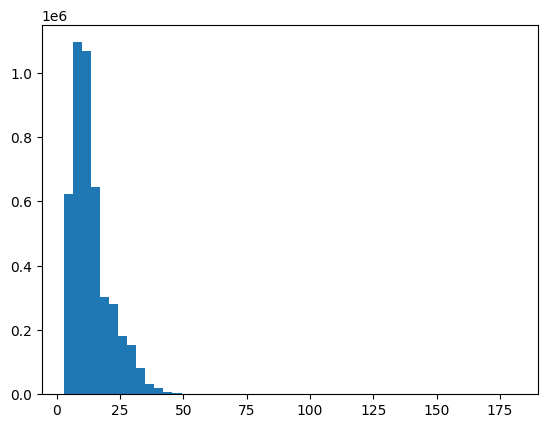

In [18]:
lst=[len(line) for line,flag in train_dataset_org]
import matplotlib.pyplot as plt
plt.hist(lst, bins=50)

In [ ]:
train_dataset=train_dataset_org
valid_dataset=valid_dataset_org
test_dataset= test_dataset_org

## 空白をランダムに抜く
20%
`noblank_ratio`（設定値は20%）の確率で入力中の空白を除く関数を定義します。このセルでは関数を定義し、データ件数を表示して保存関数も用意しますが、空白除去や保存の処理自体は呼び出していません。

In [20]:
import random

def remove_blank_flageddata(dataset):
    newdataset=[]
    for line,flag in dataset:
        if random.random()<=noblank_ratio:
            line = line.replace( 'ㅤ','')
        newdataset.append([line,flag])
    return newdataset

In [22]:
print(len(train_dataset))
print(len(valid_dataset))
print(len(test_dataset))

4492858
520452
519989


In [23]:
import gzip
import csv

def save_csv(fname,dataset):
    flag_list=[]
    with gzip.open(f'{MODEL_DIR}/{fname}','wt',encoding='utf-8') as f:
        f.write('kanji_kana,flag\n')
        for line in dataset:
            key,flag=line
            f.write(f'{key},{flag}\n')
            flag_list.append(int(flag))
    print(f'len={len(flag_list)},ok={sum(flag_list)},okratio={sum(flag_list)/len(flag_list)}')


## dataset  insample check
現在の学習・検証・テスト用データを再度走査し、学習データ内の重複と各データ間の重複を確認します。問題のある行を標準出力に表示します。

In [25]:
train_dic={}
valid_dic={}
for line in train_dataset:
    key,flag = line
    if key in train_dic:
        print(line)
    train_dic[key]=1

In [26]:
# valid data check
for line in valid_dataset:
    key,flag = line
    if key in train_dic:
        print(line)
    valid_dic[key]=1

In [27]:
# valid data check
for line in test_dataset:
    key,flag = line
    if key in train_dic or key in valid_dic:
        print(line)

['西雲_ズクモ', '0']
['持参_ネバ', '0']


## data histgram
学習データに含まれる名前ペアの文字数を集計し、長さの分布をヒストグラムで可視化します。

(array([6.228740e+05, 1.094034e+06, 1.065929e+06, 6.449330e+05,
        3.029890e+05, 2.797010e+05, 1.800820e+05, 1.537790e+05,
        8.267500e+04, 3.054200e+04, 1.931700e+04, 6.973000e+03,
        4.530000e+03, 1.564000e+03, 1.159000e+03, 5.060000e+02,
        4.070000e+02, 2.360000e+02, 1.120000e+02, 1.340000e+02,
        5.500000e+01, 7.900000e+01, 4.100000e+01, 6.600000e+01,
        3.000000e+01, 2.900000e+01, 3.000000e+01, 4.000000e+00,
        1.500000e+01, 0.000000e+00, 7.000000e+00, 7.000000e+00,
        1.000000e+00, 1.100000e+01, 3.000000e+00, 1.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 3.000000e+00]),
 array([  3.  ,   6.56,  10.12,  13.68,  17.24,  20.8 ,  24.36,  27.92,
         31.48,  35.04,  38.6 ,  42.16,  45.72,  49.28,  52.84,  56.4 ,
         59.96,  63.52,  67.08,  70.64,  74.2 ,  7

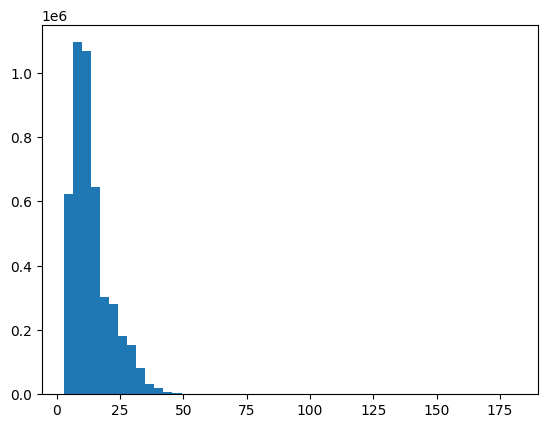

In [28]:
lst=[len(line) for line,key in train_dataset]
import matplotlib.pyplot as plt
plt.hist(lst, bins=50)

## transformer
利用可能なGPU（CUDA/MPS、なければCPU）を選び、文字列のID化、データローダー、Transformer分類器を定義します。`best.pth` がない場合に学習を実行し、学習時は生成したhard negativeも使います。検証損失・精度を記録しながら学習率を調整し、早期終了とチェックポイント保存を行います。

In [29]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using device:", device)

Using device: cuda


In [30]:
import random
import json


# train
TRAIN_YOMI={}  # length, [kana1,kana2]
TRAIN_YOM_MAXLEN=0
TRAIN_YOMI_MINLEN=999999999999
with gzip.open(f'{DATA_DIR}/{train_file}','rt',encoding='utf-8') as f:
    for line in f:
        item,flag = line.rstrip().split(',')

        siz=len(item)
        TRAIN_YOM_MAXLEN = siz if siz > TRAIN_YOM_MAXLEN else TRAIN_YOM_MAXLEN
        TRAIN_YOMI_MINLEN = siz if siz < TRAIN_YOMI_MINLEN else TRAIN_YOMI_MINLEN
        if siz not in TRAIN_YOMI:
            TRAIN_YOMI[siz]=[]
        TRAIN_YOMI[siz].append(item)


In [4]:
from torch.utils.data import Dataset, DataLoader
import unicodedata
from typing import List, Tuple, Dict, Any, Optional


TRUE=1
FALSE=0

def encode(name, max_len):
    #name=unicodedata.normalize("NFKC",name)
    k,n=name.split('_')
    k=normalize_moji(k)
    n=normalize_moji(n)
    name=k+'_'+n
    #name=normalize_moji(name)
    ids=[]
    ids.append(char2id['<bos>'])
    for c in name:
        if c == "_":
            ids.append(char2id['<sep>'])
        elif c in char2id:
            ids.append(char2id[c])
        else:
            ids.append(char2id['<unk>'])
    ids = ids[:max_len-1]
    ids.append(char2id['<eos>'])
    ids += [0] * (max_len - len(ids))
    return torch.tensor(ids)




# ---------------------------------------------------------------
import random
import csv
import gzip

# ひらがな・カタカナ変換用
KATATOP = "アイウエオカキクケコサシスセソタチツテトナニヌネノハヒフヘホマミムメモヤユヨラリルレロワヲガギグゲゴザジズゼゾダヂヅデドバビブベボパピプペポ"
KATA = "アイウエオカキクケコサシスセソタチツテトナニヌネノハヒフヘホマミムメモヤユヨラリルレロワヲンャュョガギグゲゴザジズゼゾダヂヅデドバビブベボパピプペポァィゥェォッー"


# 学習データのカナを長さ別にプールしておく（hard negative生成用）
TRAIN_KANA = {}
with gzip.open(f'{DATA_DIR}/{train_file}', 'rt', encoding='utf-8') as _f:
    for _i, _line in enumerate(_f):
        if _i == 0:
            continue
        _item, _flag = _line.rstrip().split(',')
        if int(_flag) != 1:
            continue
        _parts = _item.split('_')
        if len(_parts) < 2:
            continue
        _a = _parts[1]
        TRAIN_KANA.setdefault(len(_a), []).append(_a)


def create_random_kana(n):
    """
    長さを指定して適当に作成する
    """
    if n <= 0:
        n = 1
    moji=[]
    for i in range(n):
        if i ==0:
            idx=random.randint(0,len(KATATOP)-1)
            moji.append(KATATOP[idx])
        else:
            idx=random.randint(0,len(KATA)-1)
            moji.append(KATA[idx])
    return ''.join(moji)


def choice_random_kana(n):
    """
    train dataのカナから、指定した長さのものを選択する
    """
    lst = TRAIN_KANA.get(n)
    if not lst:
        return None
    return random.choice(lst)


def generate_negatives(kana: str, kanji: str, mix=(0.3, 0.1, 0.1, 0.1)) -> Optional[str]:
    """
    positive の読み(kana)に対して、間違った読み(負例のkana)を生成する。
    """
    n = len(kana)
    for _ in range(10):
        r = random.random()
        neg_kana = None
        if r < mix[0]:
            neg_kana = choice_random_kana(n)          # 同じ長さのかなをデータセットから選択
        elif r < mix[0] + mix[1]:
            neg_kana = create_random_kana(n + 1)      # かなの長さ+1で適当に作成
        elif r < mix[0] + mix[1] + mix[2]:
            neg_kana = create_random_kana(max(1, n - 1))  # かなの長さ-1で適当に作成
        elif r < mix[0] + mix[1] + mix[2] + mix[3]:
            siz1 = len(kanji)
            siz2 = n * 2
            st = min(siz1, siz2)
            ed = max(siz1, siz2)
            siz = random.randint(max(1, st), max(1, ed))  # 漢字長以上・かな長x2以下で適当に作成
            neg_kana = create_random_kana(siz)
        else:
            siz1 = len(kanji)
            siz2 = n * 2
            st = min(siz1, siz2)
            ed = max(siz1, siz2)
            siz = random.randint(max(1, st), max(1, ed))  # 漢字長以上・かな長x2以下でデータセットから選択
            neg_kana = choice_random_kana(siz)
        if neg_kana is not None and neg_kana != kana:
            return neg_kana
    # フォールバック
    return choice_random_kana(n) or create_random_kana(n)


# ------------------------------------------------------


import torch
import torch.nn as nn
import torch.nn.functional as F


def make_hard_negatives_batch(model, kanji_list, kana_list, max_len, K, device):
    """
    各positiveに対しK個の負例候補を生成し、
    現在のモデルが最もTRUE(本物)らしいと誤判定する候補(=hard negative)を選ぶ。
    return: [ "漢字_負例かな", ... ]  (kanji_listと同じ長さ)
    """
    cand_strings = []
    owner = []
    for pi, (k, a) in enumerate(zip(kanji_list, kana_list)):
        cands = []
        for _ in range(K):
            v = generate_negatives(a, k)
            if v is None or v == a:
                continue
            cands.append(k + "_" + v)
        if not cands:
            v = choice_random_kana(len(a)) or create_random_kana(max(1, len(a)))
            cands.append(k + "_" + v)
        for s in cands:
            cand_strings.append(s)
            owner.append(pi)

    X = torch.stack([encode(s, max_len) for s in cand_strings], dim=0).to(device)

    was_training = model.training
    model.eval()
    with torch.no_grad():
        probs_true = torch.softmax(model(X), dim=1)[:, TRUE]
    if was_training:
        model.train()

    best = {}
    best_prob = {}
    for idx, pi in enumerate(owner):
        p = probs_true[idx].item()
        if pi not in best_prob or p > best_prob[pi]:
            best_prob[pi] = p
            best[pi] = cand_strings[idx]
    return [best[pi] for pi in range(len(kanji_list))]


def build_adv_batch_flagged(model, batch_names, batch_flags, max_len, hardK, device, add_hard=False):
    """
    batch_names: ["漢字_かな", ...]
    batch_flags: [flag, ...]   flag:1 OK, flag:0 NG
    add_hard=True のとき、positiveから敵対的なhard negativeを追加生成する。
    return: X (N,L), y (N,)
    """
    kanji_pos_list = []
    kana_pos_list = []
    kanji_neg_list = []
    kana_neg_list = []
    for name, flag in zip(batch_names, batch_flags):
        k, a = name.split("_")
        if int(flag) == 1:
            kanji_pos_list.append(k)
            kana_pos_list.append(a)
        else:
            kanji_neg_list.append(k)
            kana_neg_list.append(a)

    X_list = []
    y_list = []

    if len(kanji_pos_list) > 0:
        X_pos = torch.stack(
            [encode(k + "_" + a, max_len) for k, a in zip(kanji_pos_list, kana_pos_list)],
            dim=0
        ).to(device)
        y_pos = torch.full((X_pos.size(0),), TRUE, dtype=torch.long, device=device)
        X_list.append(X_pos)
        y_list.append(y_pos)

    if len(kanji_neg_list) > 0:
        X_neg = torch.stack(
            [encode(k + "_" + a, max_len) for k, a in zip(kanji_neg_list, kana_neg_list)],
            dim=0
        ).to(device)
        y_neg = torch.full((X_neg.size(0),), FALSE, dtype=torch.long, device=device)
        X_list.append(X_neg)
        y_list.append(y_neg)

    # 敵対的hard negative（positiveから生成）
    if add_hard and len(kanji_pos_list) > 0:
        hard = make_hard_negatives_batch(model, kanji_pos_list, kana_pos_list, max_len, hardK, device)
        X_hard = torch.stack([encode(s, max_len) for s in hard], dim=0).to(device)
        y_hard = torch.full((X_hard.size(0),), FALSE, dtype=torch.long, device=device)
        X_list.append(X_hard)
        y_list.append(y_hard)

    if len(X_list) == 0:
        return None, None  # 念のため

    X = torch.cat(X_list, dim=0)
    y = torch.cat(y_list, dim=0)
    return X, y


from torch.utils.data import Dataset, DataLoader



def collate_name_flag(batch):
    names, flags = zip(*batch)
    return list(names), list(flags)

class NameDataset(Dataset):
    def __init__(self, data):
        # data: List[Tuple[str, int]]
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]   # ("漢字_かな", flag)


def create_loader(data, batch_size=32, shuffle=True):
    ds = NameDataset(data)
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_name_flag   # ← これがないと必ず死ぬ
    )

import math
import torch.nn as nn

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len,dropout):
        super().__init__()
        self.max_len = max_len
        pe = torch.zeros(max_len, d_model)  # (L, d)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # (L, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float()
                             * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)  # 偶数次元
        pe[:, 1::2] = torch.cos(position * div_term)  # 奇数次元
        pe = pe.unsqueeze(0)  # (1, L, d)
        self.register_buffer("pe", pe)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, L, d)
        L = x.size(1)
        return self.dropout( x + self.pe[:, :L, :])

class EarlyStopping:
    def __init__(self, patience, min_delta):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False

    def check(self, loss):
        if loss < self.best_loss - self.min_delta:
            self.best_loss = loss
            self.counter = 0
            return True
        else:
            self.counter += 1

        if self.counter >= self.patience:
            self.should_stop = True

        return False


import torch.nn as nn

class NameTransformer(nn.Module):
    def __init__(self, char2id, d_model, max_len,nhead, num_layers, dropout):
        super().__init__()
        self.vocab_size=len(char2id)
        self.char2id=char2id
        self.embed = nn.Embedding(self.vocab_size, d_model, padding_idx=0)

        # 位置エンコーディングを後で追加するので保持
        self.pos_encoding = PositionalEncoding(d_model, max_len, dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            batch_first=True,
            dropout=dropout          # Dropout を追加
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers)
        # 表現力を上げるためMLPヘッドにする
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, 2),
        )

    def forward(self, x):
        # padding位置(=0)をattentionから除外するマスク
        pad_mask = (x == 0)                       # (B, L) True=pad
        emb = self.embed(x)                       # (B, L, d)
        emb = self.pos_encoding(emb)              # 位置エンコーディングを付与
        h = self.encoder(emb, src_key_padding_mask=pad_mask)

        # 平均プーリング（padding を除外）
        mask = (~pad_mask).unsqueeze(-1).float()  # (B, L, 1)
        h_masked = h * mask
        lengths = mask.sum(dim=1).clamp(min=1)
        h_mean = h_masked.sum(dim=1) / lengths
        h_mean = torch.nan_to_num(h_mean)         # 念のため
        # 追加の正規化 (任意)
        h_mean = torch.nn.functional.layer_norm(h_mean, h_mean.shape[-1:])
        return self.head(h_mean)

    @classmethod
    def load(cls, path, load_model=True, map_location=None):
        chkp = torch.load(path, map_location=map_location if map_location else device)
        #args = chkp["args"]["model"].get("init_args", None) if "model" in chkp["args"] else None
        args=chkp['params']
        # 旧保存形式 fallback
        if args is None:
            args_fields = {}
            for k in ["char2id", "d_model", "max_len","nhead", "num_layers", "dropout"]:
                if k in chkp["args"]:
                    args_fields[k] = chkp["args"][k]
            args = args_fields
        model = cls(**args)
        if load_model:
            model.load_state_dict(chkp["model_state"])
        return model

from torch.utils.data import TensorDataset, DataLoader

from torch.utils.tensorboard import SummaryWriter
import torch.nn.functional as F

def consistency_loss(logits1, logits2):
    return F.mse_loss(F.softmax(logits1, dim=1),
                      F.softmax(logits2, dim=1))


import os
import math
from torch.utils.tensorboard import SummaryWriter

def train_adv_gan_with_valid(
    model,
    train_loader,           # 文字列batch
    valid_loader,           # 文字列batch
    epochs,
    max_len,
    patience,
    save_dir="./checkpoints",
    log_dir="./logs",
    model_pth="checkpoint.pth",
    model_best_pth="best.pth",
    resume=False,
    resume_pth="checkpoint.pth",
    resume_restart=False,
    hardK=hardK,
    lr=lr,
    warmup_epochs=warmup_epochs,
    use_cosine=use_cosine,
    grad_clip=grad_clip,
    min_delta=min_delta,
    use_hard_negative=True,
):
    args = locals()

    os.makedirs(save_dir, exist_ok=True)
    os.makedirs(log_dir, exist_ok=True)
    writer = SummaryWriter(log_dir=log_dir)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    es = EarlyStopping(patience=patience, min_delta=min_delta)
    est = EarlyStopping(patience=patience, min_delta=min_delta)  # training also check

    # Warmup + Cosine
    def lr_schedule(epoch):
        if epoch < warmup_epochs:
            return (epoch + 1) / max(1, warmup_epochs)
        if use_cosine:
            t = (epoch - warmup_epochs) / max(1, (epochs - warmup_epochs))
            return 0.5 * (1 + math.cos(math.pi * t))
        return 1.0

    ckpt_path = os.path.join(save_dir, model_pth)
    best_path = os.path.join(save_dir, model_best_pth)
    resume_ckpt_path = os.path.join(save_dir, resume_pth)

    start_epoch = 0

    # ---- resume ----
    if resume and os.path.exists(resume_ckpt_path):
        ckpt = torch.load(resume_ckpt_path, map_location=device)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optim_state"])

        # early stopping state
        if "best_val_loss" in ckpt:
            es.best_loss = ckpt["best_val_loss"]

        if "best_train_loss" in ckpt:
            est.best_loss = ckpt['best_train_loss']

        if not resume_restart:
            start_epoch = ckpt.get("epoch", -1) + 1

        print(f"[resume] loaded: {resume_ckpt_path} (start_epoch={start_epoch}, best_val_loss={es.best_loss}, best_train_loss={est.best_loss})")

    # ---- train loop ----
    for epoch in range(start_epoch, epochs):
        # set lr
        cur_lr = lr * lr_schedule(epoch)
        for pg in optimizer.param_groups:
            pg["lr"] = cur_lr

        # ---- train ----
        model.train()
        tr_loss_sum = 0.0
        tr_correct = 0
        tr_count = 0

        for data in train_loader:
            # 学習時のみ敵対的hard negativeを追加する
            X, y = build_adv_batch_flagged(
                model, data[0], data[1], max_len,
                hardK=hardK, device=device, add_hard=use_hard_negative
            )

            optimizer.zero_grad(set_to_none=True)
            logits = model(X)

            if torch.isnan(logits).any() or torch.isinf(logits).any():
                print("Skip batch (bad logits)")
                continue

            loss = loss_fn(logits, y)
            if torch.isnan(loss) or torch.isinf(loss):
                print("Skip batch (bad loss)")
                continue

            loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

            tr_loss_sum += loss.item() * X.size(0)
            tr_correct += (logits.argmax(1) == y).sum().item()
            tr_count += X.size(0)

        tr_loss = tr_loss_sum / max(1, tr_count)
        tr_acc = tr_correct / max(1, tr_count)

        # ---- valid ----
        # 検証は固定の負例（データセットのflag）のみで評価する
        model.eval()
        va_loss_sum = 0.0
        va_correct = 0
        va_count = 0

        with torch.no_grad():
            for data in valid_loader:
                Xv, yv = build_adv_batch_flagged(
                    model, data[0], data[1], max_len,
                    hardK=hardK, device=device, add_hard=False
                )
                pv = model(Xv)
                lv = loss_fn(pv, yv)

                va_loss_sum += lv.item() * Xv.size(0)
                va_correct += (pv.argmax(1) == yv).sum().item()
                va_count += Xv.size(0)

        va_loss = va_loss_sum / max(1, va_count)
        va_acc = va_correct / max(1, va_count)

        # ---- log ----
        writer.add_scalar("train/loss", tr_loss, epoch)
        writer.add_scalar("train/acc", tr_acc, epoch)
        writer.add_scalar("valid/loss", va_loss, epoch)
        writer.add_scalar("valid/acc", va_acc, epoch)
        writer.add_scalar("lr", cur_lr, epoch)
        writer.add_scalar("hardK", hardK, epoch)

        print(f"Epoch {epoch} | train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} | val_loss={va_loss:.4f} val_acc={va_acc:.3f} | lr={cur_lr:.6g} hardK={hardK}")


        def save_model(fname):
            # ---- save checkpoint every epoch ----
            torch.save({
                "params":  {
                    "char2id": model.char2id,
                    "d_model": model.embed.embedding_dim,
                    "max_len": model.pos_encoding.max_len,
                    "nhead": model.encoder.layers[0].self_attn.num_heads,
                    "num_layers": len(model.encoder.layers),
                    "dropout": model.encoder.layers[0].dropout.p if hasattr(model.encoder.layers[0].dropout, "p") else 0.0
                },
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optim_state": optimizer.state_dict(),
                "best_val_loss": es.best_loss,
                "best_train_loss": est.best_loss
            }, fname)

        save_model(ckpt_path)

        # ---- EarlyStopping判定: andの短絡評価を避け、必ず両方のcheckを呼ぶ ----
        val_improved = es.check(va_loss)
        train_improved = est.check(tr_loss)

        # ---- best save (val_loss と train_loss がともに改善したとき) ----
        if val_improved and train_improved:
            save_model(best_path)


        if es.should_stop and est.should_stop:
            print("Early stopping:", epoch)
            break

    writer.close()

In [32]:
if debug:
    train_dataset=train_dataset[:1000]
    valid_dataset=valid_dataset[:100]

In [33]:
train_loader = create_loader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

valid_loader = create_loader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=True
)

model = NameTransformer(
    char2id=char2id,
    d_model=d_model,
    max_len=max_len,
    nhead=nhead,
    num_layers=num_layer,
    dropout=dropout
).to(device)

if device.type == "mps":
    # MPS では TransformerEncoder の nested tensor 高速化パス
    # (aten::_nested_tensor_from_mask_left_aligned) が未実装のため無効化する
    model.encoder.use_nested_tensor = False

In [34]:
import os
if not os.path.exists(f"{MODEL_DIR}/best.pth"):
    train_adv_gan_with_valid(
        model,
        train_loader,
        valid_loader,
        epochs=epochs,
        max_len=max_len,
        patience=patience,
        save_dir=f"{MODEL_DIR}",
        log_dir=f"{LOG_DIR}",
        model_pth="checkpoint.pth",
        model_best_pth="best.pth",
        resume=True,
        resume_pth="checkpoint.pth",
        resume_restart=False,
        hardK=hardK,      # 4〜8推奨（大きいほど遅い）
        lr=lr,
        warmup_epochs=warmup_epochs,
        use_cosine=use_cosine,
        grad_clip=grad_clip,
        min_delta=min_delta,
        use_hard_negative=use_hard_negative
    )


/mnt/src2/kanjikana-private/venv/lib64/python3.12/site-packages/torch/nn/modules/transformer.py:409: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. (Triggered internally at ../aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(output, src_key_padding_mask.logical_not(), mask_check=False)


Epoch 0 | train_loss=0.4213 train_acc=0.779 | val_loss=0.4117 val_acc=0.758 | lr=3e-05 hardK=4


Epoch 1 | train_loss=0.3604 train_acc=0.817 | val_loss=0.3276 val_acc=0.844 | lr=6e-05 hardK=4


Epoch 2 | train_loss=0.2911 train_acc=0.864 | val_loss=0.2726 val_acc=0.880 | lr=9e-05 hardK=4


Epoch 3 | train_loss=0.2719 train_acc=0.876 | val_loss=0.2708 val_acc=0.879 | lr=0.00012 hardK=4


Epoch 4 | train_loss=0.2721 train_acc=0.876 | val_loss=0.2635 val_acc=0.885 | lr=0.00015 hardK=4


... (45 outputs left out)

Epoch 50 | train_loss=0.2566 train_acc=0.885 | val_loss=0.3073 val_acc=0.870 | lr=0.000176047 hardK=4


Epoch 51 | train_loss=0.2565 train_acc=0.885 | val_loss=0.2621 val_acc=0.888 | lr=0.000170876 hardK=4


Epoch 52 | train_loss=0.2565 train_acc=0.885 | val_loss=0.3656 val_acc=0.851 | lr=0.000165679 hardK=4


Early stopping: 52


# 推論
テストデータを読み込み、保存済みの最良モデルで二値分類を実行します。予測クラスと損失・正解率を計算し、ID列を文字列に戻すためのデコード処理も定義します。

In [35]:
def decode(ids):
    chars = []
    for i in ids:
        ch = id2char.get(int(i), '<unk>')

        if ch == '<bos>':
            continue
        if ch == '<eos>':
            break
        if ch == '<sep>':
            chars.append('_')
        elif ch not in ['<pad>']:
            chars.append(ch)

    return "".join(chars)


In [36]:
test_loader = create_loader(
    test_dataset,
    batch_size=1,
    shuffle=False
)

In [37]:
def testing(model,test_loader):
        model.eval()
        test_loss_sum = 0.0
        test_correct = 0
        test_count = 0
        loss_fn = nn.CrossEntropyLoss()
        with torch.no_grad():
            for data in test_loader:
                Xv, yv = build_adv_batch_flagged(model, data[0],data[1], max_len,hardK=hardK, device=device)
                pv = model(Xv)
                lv = loss_fn(pv, yv)

                test_loss_sum += lv.item() * Xv.size(0)
                test_correct += (pv.argmax(1) == yv).sum().item()
                test_count += Xv.size(0)

        test_loss = test_loss_sum / max(1, test_count)
        test_acc = test_correct / max(1, test_count)
        return test_loss,test_acc

In [38]:
model = NameTransformer.load(f"./{MODEL_DIR}/best.pth")
model.to(device)
model.eval()

print(testing(model,test_loader))



/var/tmp/pbs.14526.fcpvansv01/ipykernel_355003/694197507.py:345: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  chkp = torch.load(path, map_location=map_location if map_locat

(0.2556303453732775, 0.8895245860970136)


## analysis
確率分布を見る
テストデータについて各クラスの予測確率を求め、正しく分類した例と誤分類した例に分けます。それぞれの確率をヒストグラムにして、予測の確信度の分布を確認します。

In [39]:

def predict(name):
    x = encode(name,max_len).unsqueeze(0).to(device)
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[0]
    return {"TRUE": float(p[1]), "FALSE": float(p[0])}, TRUE if  float(p[1])>float(p[0]) else FALSE

In [40]:
tp_prob=[]
fp_prob=[]
tn_prob=[]
fn_prob=[]
all_prob=[]
for name, yv in test_dataset: # yv:1 ok, 2:NG
    res = predict(name)
    all_prob.append(res[0]['TRUE'])
    if int(res[1])==int(yv):
        if int(res[1])==1:
            tp_prob.append(res[0]['TRUE'])
        else:
            tn_prob.append(res[0]['FALSE'])
    else:
        if int(res[1])==1:
            fp_prob.append(res[0]['TRUE']) # true予想が間違っていた時のTRUEの確率
        else:
            fn_prob.append(res[0]['FALSE']) # false予想が間違っていた時のFALSEの確率

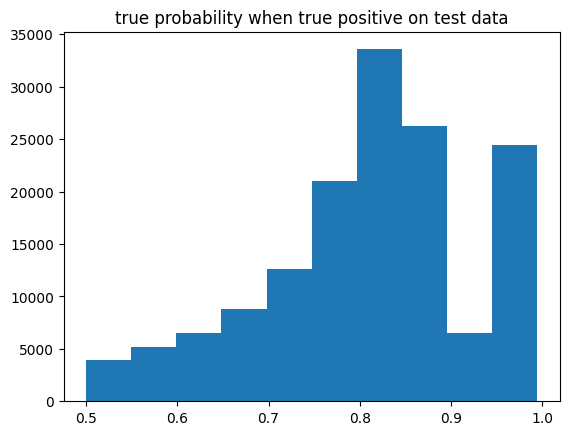

In [41]:
import matplotlib.pyplot as plt

plt.hist(tp_prob)
plt.title('true probability when true positive on test data')
plt.show()

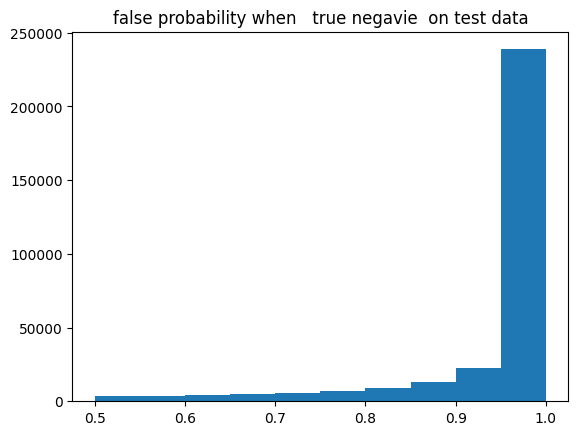

In [42]:
plt.hist(tn_prob)
plt.title('false probability when   true negavie  on test data')
plt.show()

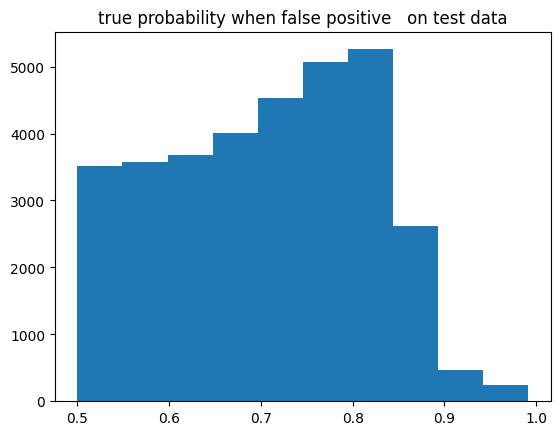

In [43]:
plt.hist(fp_prob)
plt.title('true probability when false positive   on test data')
plt.show()

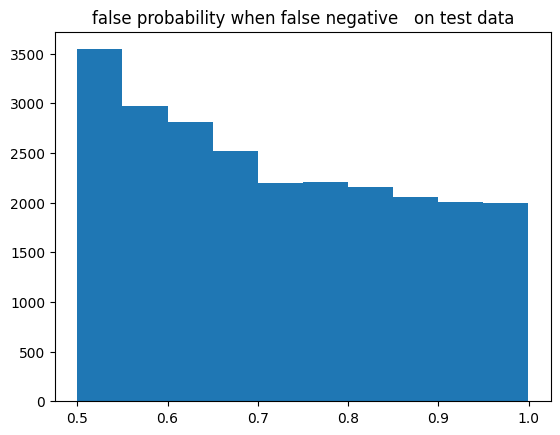

In [44]:
plt.hist(fn_prob)
plt.title('false probability when false negative   on test data')
plt.show()

In [45]:
!date

2026年  8月 11日 火曜日 05:10:32 JST


# torch scriptに変換
最良チェックポイントからモデルと設定を読み込み、推論用の入力長を20に設定します。モデルをCPU上でTorchScriptにトレースしてfreezeし、`.pt` ファイルとして保存するとともに、推論に必要な設定と文字ID辞書もJSONで書き出します。

In [5]:
import torch
import json

max_len=20
out_path=f'{MODEL_DIR}/model_scripted{branch_suffix}_{ver}.pt'
model_path=f'{MODEL_DIR}/best.pth'

In [6]:
chpt = torch.load(model_path, map_location=torch.device("cpu"))

params=chpt['params']
del params['char2id']
with open(f"{MODEL_DIR}/params{branch_suffix}_{ver}.json","w",encoding='utf-8') as f:
    json.dump(chpt['params'],f,ensure_ascii=False,indent=2)


/tmp/ipykernel_1323836/3732096385.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  chpt = torch.load(model_path, map_location=torch.device("cpu"))


In [7]:
# 1) checkpoint(best.pth) からモデル復元
model = NameTransformer.load(f"{MODEL_DIR}/best.pth", load_model=True, map_location="cpu")

model = model.to("cpu")
model.eval()

# 2) TorchScript 用のダミー入力（(B,L) int64）
# 重要: 全てゼロだと nested tensor 変換エラーが発生するため、
# 実際のトークン ID を含める。最初のいくつかのトークンを 1 で埋める
dummy = torch.ones((1, max_len), dtype=torch.long, device="cpu")

# 3) trace（推論専用）
with torch.no_grad():
    traced = torch.jit.trace(model, dummy, strict=False)
    traced = torch.jit.freeze(traced)

# 4) 保存
os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
traced.save(out_path)


# char2id
with open(f"{MODEL_DIR}/char2id{branch_suffix}_{ver}.json","w",encoding='utf-8') as f:
    json.dump(model.char2id,f,ensure_ascii=False,indent=2)

/tmp/ipykernel_1323836/694197507.py:345: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  chkp = torch.load(path, map_location=map_location if map_location else device)
/mnt/sr

In [8]:
!date

2026年  8月 24日 月曜日 14:41:49 JST
